# MongoDB 資料模型設計工作坊
## 打造 KFC 會員忠誠度平台

歡迎參加！在這場實作工作坊中，你將使用真實的 Atlas 叢集，一步步為速食店的
會員忠誠度計畫設計資料模型。

**議程**

| 部分 | 主題 |
|---|---|
| 0 | 環境設定與連線至 Atlas |
| 1 | 內嵌（Embedding）vs. 參照（Referencing）——最基礎的決策 |
| 2 | 延伸參照模式（Extended Reference Pattern） |
| 3 | 一步步進行資料模型設計 |
| 4 | 深入資料模型設計模式：計算模式、屬性模式、離群值模式、繼承模式——以及「無界陣列」反模式 |
| 5 | 最終整合資料模型 + 期末綜合練習 |
| 6 | 總結與速查表 |

> 💡 每個模式章節都遵循相同流程：**問題 → 解法 → 範例演練 → 練習題**。
> 練習題下方附有可收合的「解答」區塊——建議先自己動手試試看！

---
# Part 0 — 環境設定

每位學員共用**同一個 Atlas 叢集**，但各自使用**獨立的資料庫（database）**。
你的 `.env` 檔案決定你要使用哪一個資料庫（`DB_NAME`）——請務必確認這個名稱
是你專屬、不會與他人重複的。如果還沒設定好，請參考 `README.md`。

In [2]:
import sys
sys.path.append("..")  # 讓我們可以從 repo 根目錄匯入 workshop_utils.py

from workshop_utils import (
    get_db, reset_workshop_db, pprint_doc, pprint_docs,
    explain_summary, time_it, doc_size_bytes,
    generate_stores, generate_menu_items, generate_customers,
    generate_orders, generate_point_transactions_for_customer,
    generate_polymorphic_rewards,
)
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timezone
from bson import ObjectId

db = get_db()

Connected to Atlas cluster. Using database: 'kfc_loyalty_niko'


In [3]:
# 從乾淨的狀態開始。這個 cell 在工作坊的任何時間點重複執行都是安全的。
reset_workshop_db(db)

Dropped collections in 'kfc_loyalty_niko': customers, stores, menu_items, orders, point_transactions, rewards, redemptions, customer_overflow


---
# Part 1 — 內嵌（Embedding）vs. 參照（Referencing）

這是 MongoDB 資料模型設計中最重要的單一決策。做對了，查詢會又快又簡單；
做錯了，你會一直在跟資料庫「打架」。

### 決策框架

| 考量因素 | 傾向內嵌（Embed） | 傾向參照（Reference） |
|---|---|---|
| **基數（Cardinality）** | 1:1 或 1:少量 | 1:多 或 1:海量 |
| **是否一起讀取？** | 是，幾乎總是一起被取用 | 否，通常各自獨立查詢 |
| **成長幅度** | 有界，維持小規模 | 無界 / 隨時間持續成長 |
| **更新頻率** | 很少變動，或與父文件一起變動 | 子資料的更新頻率遠高於父文件 |
| **原子性需求** | 需要單一文件的原子更新 | 可容忍跨文件的最終一致性 |
| **文件大小** | 遠低於 16MB | 有逼近 16MB 的風險 |

經驗法則：**把「會一起查詢」且「維持小規模」的資料內嵌；
把「會無限成長」或「會被獨立查詢」的資料用參照。**

### 1.1 內嵌範例 — 顧客聯絡資訊（1:1，一起讀取）

顧客的聯絡資訊幾乎總是**跟著顧客本身**一起被讀取、很少變動，而且資料量
小且有界。這是內嵌的最佳候選情境。

In [4]:
sample_customer = {
    "_id": ObjectId(),
    "name": "Jordan Lee",
    "tier": "Gold",
    # 內嵌：1:1 關係，永遠跟顧客一起讀取，資料小且穩定
    "contactInfo": {
        "email": "jordan.lee@example.com",
        "phone": "+1-502-555-0199",
        "address": {"city": "Louisville", "state": "KY", "zip": "40202"},
    },
}
db.customers.insert_one(sample_customer)
pprint_doc(db.customers.find_one({"_id": sample_customer["_id"]}))

{
  "_id": "6adad2f75e0795028f227436",
  "name": "Jordan Lee",
  "tier": "Gold",
  "contactInfo": {
    "email": "jordan.lee@example.com",
    "phone": "+1-502-555-0199",
    "address": {
      "city": "Louisville",
      "state": "KY",
      "zip": "40202"
    }
  }
}


### 1.2 參照範例 — 顧客 → 訂單（1:多，無界成長）

一位顧客可能在數年間累積上千筆訂單。訂單通常是被獨立查詢的（例如「幫我
調出訂單 #1234」），而且這個關係是無界成長的——這是典型該用**參照**、
而非內嵌的情境。

In [5]:
stores = generate_stores(n=6)
menu_items = generate_menu_items()
db.stores.insert_many(stores)
db.menu_items.insert_many(menu_items)

customers = generate_customers(n=60, store_ids=[s["_id"] for s in stores])
db.customers.insert_many(customers)

# 訂單用「參照」指向顧客（存 id），而不是把完整訂單歷史內嵌進顧客文件裡。
order_example = {
    "_id": ObjectId(),
    "customerId": customers[0]["_id"],   # <-- 這是參照，不是內嵌
    "storeId": stores[0]["_id"],
    "items": [{"sku": "ZNG-BURGER", "qty": 1, "unitPrice": 7.49}],
    "total": 7.49,
    "orderedAt": datetime.now(timezone.utc),
}
db.orders.insert_one(order_example)

print("顧客文件（小且穩定）：")
pprint_doc(db.customers.find_one({"_id": customers[0]["_id"]}))
print("\n訂單文件（用 id 參照顧客）：")
pprint_doc(db.orders.find_one({"_id": order_example["_id"]}))

顧客文件（小且穩定）：
{
  "_id": "6adad2f95e0795028f227437",
  "name": "Melinda Cameron",
  "email": "perezantonio@example.com",
  "phone": "(541)639-5376x7242",
  "homeStoreId": "STORE-1005",
  "joinedAt": "2025-09-04T05:05:51.696000",
  "tier": "Bronze",
  "loyaltyStats": {
    "lifetimePoints": 0,
    "currentBalance": 0,
    "totalOrders": 0,
    "lastComputedAt": "2025-09-04T05:05:51.696000"
  },
  "hasExtendedHistory": false
}

訂單文件（用 id 參照顧客）：
{
  "_id": "6adad2f95e0795028f227473",
  "customerId": "6adad2f95e0795028f227437",
  "storeId": "STORE-1000",
  "items": [
    {
      "sku": "ZNG-BURGER",
      "qty": 1,
      "unitPrice": 7.49
    }
  ],
  "total": 7.49,
  "orderedAt": "2026-10-23T03:22:33.600000"
}


### 📝 練習題 1

針對以下每一組關係，請判斷應該用**內嵌（embed）**還是**參照
（reference）**，並用上方的決策框架表格說明理由：

1. `Customer` ↔ `StoreVisit`（顧客每次造訪實體門市的打卡事件——一年可能
   發生上百次）
2. `Order` ↔ `OrderItems`（單筆訂單中的 1～6 個品項明細）
3. `Customer` ↔ `FavoriteStore`（顧客標記為預設取餐門市的那一間店）

請先寫下你的答案，再展開下方解答。

<details>
<summary>✅ 點此展開解答</summary>

1. **`Customer` ↔ `StoreVisit` → 參照。** 這是無界的 1:多關係（一年上百筆、
   持續累積），通常被獨立查詢（例如分析用的「過去 30 天的到店紀錄」），
   而且不會每次請求都跟顧客基本資料一起被讀取。若內嵌，最終會重現
   「無界陣列」反模式（見 Part 4.1！）。

2. **`Order` ↔ `OrderItems` → 內嵌。** 1:少量關係，永遠一起被讀寫
   （不會有「只取訂單、不取品項」的情境），在常見情況下資料量有界
   （就幾個品項）。這是教科書等級的內嵌案例——*但是*請參考 Part 4.4
   （離群值模式），看看當罕見的「團體訂餐」有 200 個品項而非 3 個時
   會發生什麼事。

3. **`Customer` ↔ `FavoriteStore` → 用 id 做參照，不要內嵌整份門市文件。**
   雖然是 1:1 關係，但「門市」本身是一個共享、會被多位顧客參照、且會
   獨立更新的實體——把整份門市文件複製進每一位顧客文件裡，會造成資料
   重複，而且當門市的營業時間／地址變動時就會產生過時資料。應該儲存
   一個 `favoriteStoreId` 參照欄位即可。（如果你只需要 1～2 個顯示用
   欄位，例如門市名稱，這其實正是**延伸參照模式**的絕佳應用情境——
   詳見 Part 2！）

</details>

---
# Part 2 — 延伸參照模式（Extended Reference Pattern）

### 問題

我們剛剛決定 `Order → Customer` 應該用**參照**（1:多，無界成長）。但我們
App 的訂單列表畫面，需要在每一筆訂單旁邊顯示顧客的**姓名與會員等級**。
如果只用純參照，每一次訂單列表查詢都得對 `customers` 做一次 `$lookup`
關聯查詢。

在大規模情境下（每次頁面載入列出數千筆訂單、且有大量並行使用者），
為了幾乎不會變動的資料，付出這麼多次關聯查詢的成本並不划算。

### 解法

**延伸參照模式**：保留參照欄位（`customerId`），但同時把被參照文件中
*少量、變動緩慢*的欄位，直接複製一份到參照方的文件裡。你同時獲得了
參照的語意（不會整份複製顧客資料），以及針對實際顯示欄位如內嵌般的
讀取效能。

In [6]:
# 用延伸參照模式重建 `orders`：每筆訂單內嵌一份小型快照
# （customerId、displayName、tier），而不是只存 customerId。
db.orders.drop()
store_ids = [s["_id"] for s in stores]
orders = generate_orders(customers, store_ids, menu_items, n=10000)
db.orders.insert_many(orders)

print("使用延伸參照的訂單文件：")
pprint_doc(db.orders.find_one())

使用延伸參照的訂單文件：
{
  "_id": "6adad2fd5e0795028f227474",
  "customerRef": {
    "customerId": "6adad2f95e0795028f22745a",
    "displayName": "Paul Carroll",
    "tier": "Bronze"
  },
  "storeId": "STORE-1005",
  "items": [
    {
      "sku": "ZNG-BURGER",
      "name": "Zinger Burger",
      "qty": 2,
      "unitPrice": 7.49
    }
  ],
  "total": 14.98,
  "pointsEarned": 14,
  "orderedAt": "2026-06-21T16:00:45.577000"
}


### 並排比較

讓我們實際驗證這個論點：建立一個**純參照版本**的姊妹集合（只存
`customerId`），然後比較「列出最近訂單並顯示顧客姓名與等級」這個查詢，
分別用 `$lookup` 和延伸參照欄位來實作的差異。

只用一個很小的頁面大小（例如 20 筆）來做單次比較，其實很容易產生誤導：
在索引欄位上做 `$lookup`，*每一筆*的額外成本其實很小，當只處理少量資料
時，這點額外成本很容易被正常的網路／量測雜訊蓋過去。真正的重點在於
`$lookup` 的成本會**隨著你要 join 的筆數而線性增加**（想像一下：後台
匯出報表，或是使用者不斷往下滑的無限捲動動態牆），而延伸參照查詢的
成本並不會這樣增加——所以讓我們把頁面大小逐步拉大，看看這個差距
如何被拉開。

In [7]:
# 純參照版本的相同資料，僅供比較使用。
db.orders_pure_ref.drop()
pure_ref_docs = [
    {
        "_id": o["_id"],
        "customerId": o["customerRef"]["customerId"],
        "storeId": o["storeId"],
        "items": o["items"],
        "total": o["total"],
        "orderedAt": o["orderedAt"],
    }
    for o in orders
]
db.orders_pure_ref.insert_many(pure_ref_docs)

db.orders.create_index([("orderedAt", -1)])
db.orders_pure_ref.create_index([("orderedAt", -1)])
db.customers.create_index([("_id", 1)])  # 預設就有，這裡只是明確列出
print("比較用的集合已準備完成。")

比較用的集合已準備完成。


In [9]:
import statistics

LIMITS = [100, 500, 2000, 8000]
N_TRIALS = 5


def lookup_pipeline(limit):
    return [
        {"$sort": {"orderedAt": -1}},
        {"$limit": limit},
        {"$lookup": {
            "from": "customers",
            "localField": "customerId",
            "foreignField": "_id",
            "as": "customer",
        }},
        {"$unwind": "$customer"},
        {"$project": {
            "total": 1, "orderedAt": 1,
            "displayName": "$customer.name", "tier": "$customer.tier",
        }},
    ]


def make_lookup_query(limit):
    pipeline = lookup_pipeline(limit)
    return lambda: list(db.orders_pure_ref.aggregate(pipeline))


def make_extended_query(limit):
    return lambda: list(
        db.orders.find({}, {"total": 1, "orderedAt": 1, "customerRef": 1})
        .sort("orderedAt", -1)
        .limit(limit)
    )


# 先為每種頁面大小建立兩種查詢，再全部預熱一次後才開始計時，避免
# 第一組計時結果承受首次執行／查詢計畫／快取初始化的額外影響。
queries = {
    limit: (make_lookup_query(limit), make_extended_query(limit))
    for limit in LIMITS
}
for limit_index, limit in enumerate(LIMITS):
    lookup_query, extended_query = queries[limit]
    prime_order = (lookup_query, extended_query)
    if limit_index % 2:
        prime_order = prime_order[::-1]
    for query in prime_order:
        query()


# 每次試驗成對計時，並交替先測哪一種策略，以降低固定執行順序造成的
# 偏差。共測 5 次，在 Atlas 上取中位數會比少量試驗更穩定。
timed_rows = {limit: {"lookup": [], "extended": []} for limit in LIMITS}
for trial in range(N_TRIALS):
    for limit_index, limit in enumerate(LIMITS):
        lookup_query, extended_query = queries[limit]
        run_lookup_first = (trial + limit_index) % 2 == 0
        trial_order = (
            [("lookup", lookup_query), ("extended", extended_query)]
            if run_lookup_first
            else [("extended", extended_query), ("lookup", lookup_query)]
        )
        for strategy, query in trial_order:
            timed_rows[limit][strategy].append(time_it(query)[1])


sweep_rows = []
for limit in LIMITS:
    lookup_ms = statistics.median(timed_rows[limit]["lookup"])
    extended_ms = statistics.median(timed_rows[limit]["extended"])
    sweep_rows.append({
        "limit（join／回傳筆數）": limit,
        "純參照 $lookup（ms）": round(lookup_ms, 2),
        "延伸參照（ms）": round(extended_ms, 2),
        "加速倍數": round(lookup_ms / extended_ms, 1) if extended_ms > 0 else None,
    })

sweep_df = pd.DataFrame(sweep_rows)
sweep_df

,limit（join／回傳筆數）,純參照 $lookup（ms）,延伸參照（ms）,加速倍數
0,100,48.40,44.35,1.1
1,500,115.14,109.29,1.1
2,2000,214.43,188.86,1.1
3,8000,751.06,511.75,1.5


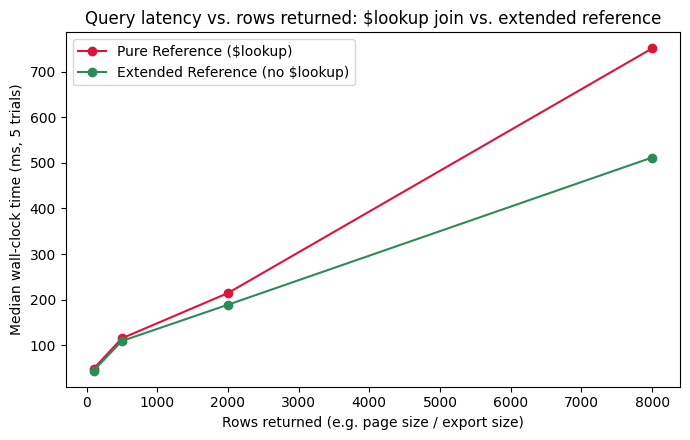

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sweep_df["limit（join／回傳筆數）"], sweep_df["純參照 $lookup（ms）"],
        marker="o", label="Pure Reference ($lookup)", color="crimson")
ax.plot(sweep_df["limit（join／回傳筆數）"], sweep_df["延伸參照（ms）"],
        marker="o", label="Extended Reference (no $lookup)", color="seagreen")
ax.set_title("Query latency vs. rows returned: $lookup join vs. extended reference")
ax.set_xlabel("Rows returned (e.g. page size / export size)")
ax.set_ylabel("Median wall-clock time (ms, 5 trials)")
ax.legend()
plt.tight_layout()
plt.show()

In [22]:
# 機制驗證：在最大的頁面大小下，透過 .explain() 確認「為什麼」
# $lookup 版本比較慢——是因為檢查了更多文件，而不只是耗時數字比較大。
biggest_limit = LIMITS[-1]
pipeline = lookup_pipeline(biggest_limit)

explain_ext = db.orders.find(
    {}, {"total": 1, "orderedAt": 1, "customerRef": 1}
).sort("orderedAt", -1).limit(biggest_limit).explain()

# 聚合管線的 explain 要透過 db.command(..., explain=True) 取得
# （驅動程式的 collection.aggregate() 並不支援 explain=True 這個參數，
#  即便是最新版的 pymongo 也一樣——驅動程式會主動擋下並要求改用
#  Database.command）。
explain_lookup = db.command({
    "explain": {
        "aggregate": "orders_pure_ref",
        "pipeline": pipeline,
        "cursor": {},
    },
    "verbosity": "executionStats",
})

comparison_ext = explain_summary(explain_ext, label=f"延伸參照（limit={biggest_limit}）")

# 聚合管線的 explain 輸出是「每個管線階段一筆」，而不是單一的
# 頂層 executionStats 區塊，所以我們把各階段加總：一開始的 $cursor
# 階段（餵進管線的集合掃描）加上 $lookup 階段（每筆訂單額外多檢查
# 一份文件，用於 join）。實際採用的 $lookup 策略（索引巢狀迴圈 vs.
# 雜湊 join）可能會不同，所以這裡用 .get() 做防呆，避免欄位不存在時
# 直接出錯。
cursor_stats = explain_lookup["stages"][0]["$cursor"]["executionStats"]
lookup_stage = next((s["$lookup"] for s in explain_lookup["stages"] if "$lookup" in s), {})
total_docs_examined = cursor_stats["totalDocsExamined"] + lookup_stage.get(
    "totalDocsExamined", cursor_stats["nReturned"]  # 大約每筆訂單會碰觸 1 份顧客文件
)
total_time_ms = cursor_stats["executionTimeMillis"] + sum(
    s.get("executionTimeMillisEstimate", 0) for s in explain_lookup["stages"]
)

comparison_lookup_row = pd.DataFrame([{
    "label": f"純參照（$lookup, limit={biggest_limit}）",
    "stage": "AGGREGATE + $lookup join",
    "executionTimeMillis": total_time_ms,
    "totalDocsExamined": total_docs_examined,
    "totalKeysExamined": cursor_stats["totalKeysExamined"] + lookup_stage.get("totalKeysExamined", 0),
    "nReturned": comparison_ext["nReturned"][0],
}])
pd.concat([comparison_lookup_row, comparison_ext], ignore_index=True)

,label,stage,executionTimeMillis,totalDocsExamined,totalKeysExamined,nReturned
0,"純參照（$lookup, limit=8000）",AGGREGATE + $lookup join,842,16000,8000,8000
1,延伸參照（limit=8000）,LIMIT,25,8000,8000,8000


注意這個差距**會隨著頁面大小變大而不斷擴大**：在 100 筆的時候兩者很
接近（每筆的 $lookup 額外成本還小到不太有感），但到了 8,000 筆時，
`$lookup` 版本在聚合管線內部要對 `customers` 做數千次額外的索引查找，
而延伸參照查詢的成本幾乎沒有變化——因為不論你要求多少筆資料，它
完全不會去碰 `customers` 集合。

### ⚠️ 取捨：資料過時（Staleness）

如果顧客的 `tier` 改變了（例如 Silver → Gold），所有**過去**的訂單
仍然會顯示舊的等級快照——這通常**沒問題**（訂單本來就是歷史紀錄），
但如果你需要讓延伸複製的資料保持最新（例如進行中訂單上要顯示「目前
等級徽章」），你就必須主動讓它保持同步：

- **應用層雙寫**：更新 `customers.tier` 的同時，在同一個請求裡也更新
  最近／進行中訂單的 `customerRef.tier`。
- **Change Streams（異動串流）**：監聽 `customers` 的等級變動，非同步地
  修補散落各處的反正規化副本。

延伸參照用一點點寫入端的複雜度，換取讀取端大幅的簡化與效能提升——
當讀取量遠大於寫入量時（這幾乎是所有忠誠度 App 訂單歷史介面的常態），
這個交換是值得的。

### 📝 練習題 2

訂單同時也參照了 `storeId`。請設計你會加進訂單文件裡的**延伸參照
欄位**，讓收據畫面可以顯示門市名稱與城市，而不需要再發一次查詢。
你會選哪些欄位？為什麼選這些、而不選其他欄位（例如門市的完整地址
或電話）？

<details>
<summary>✅ 點此展開解答</summary>

```json
{
  "_id": "...",
  "storeId": "STORE-1002",
  "storeRef": { "storeId": "STORE-1002", "name": "KFC Atlanta #1002", "city": "Atlanta, GA" },
  "...": "..."
}
```

選擇那些**（a）實際會顯示在訂單／收據上**、而且**（b）很少變動**的
欄位——`name` 和 `city` 同時符合這兩個條件。跳過 `address`（地址）
或 `phone`（電話）：收據上用不到這些資訊，放進去只會讓每一筆訂單
文件變大，卻換不到任何讀取效能上的好處；而且 `address` 其實是會變的
（門市搬遷），這會導致舊收據上留著過時資料，卻又沒有像 `tier` 那樣
明確「這沒關係」的理由可以支撐。

```python
db.orders.update_many({}, [
    {"$lookup": {
        "from": "stores", "localField": "storeId",
        "foreignField": "_id", "as": "_store"
    }},
    {"$set": {"storeRef": {
        "storeId": "$storeId",
        "name": {"$first": "$_store.name"},
        "city": {"$first": "$_store.city"},
    }}},
    {"$unset": "_store"},
])
```
</details>

---
# Part 3 — 一步步設計忠誠度平台資料模型

好的資料模型設計，應該從**存取模式（access patterns）**出發，而不是
從實體（entity）出發。讓我們照著在真實專案中會走的流程，實際演練一遍。

### 3.1 實體（Entities）

- **Customer（顧客）** — 基本資料、會員等級、點數餘額
- **Store（門市）** — 實體門市據點
- **Menu Item（菜單品項）** — 商品目錄
- **Order（訂單）** — 一筆消費，包含品項明細
- **Point Transaction（點數交易）** — 一次累積或兌換事件
- **Reward（獎勵）** — 可用點數兌換的東西（有多種類型）
- **Redemption（兌換紀錄）** — 顧客實際兌換某個獎勵的紀錄

### 3.2 存取模式（請在建模*之前*先把這些寫下來！）

| # | 存取模式 | 發生頻率 | 延遲需求 |
|---|---|---|---|
| 1 | 載入顧客基本資料 + 目前點數餘額 | 極高（每次打開 App） | 要快 |
| 2 | 列出顧客最近的訂單，並顯示門市/顧客的相關資訊 | 高 | 要快 |
| 3 | 顯示顧客完整的點數交易歷史（分頁） | 中 | 可以稍慢一點 |
| 4 | 記錄一筆新訂單 + 核發點數 | 高（每次消費） | 要快，且必須可靠 |
| 5 | 瀏覽獎勵目錄，依資格條件篩選（等級、門市、星期） | 高 | 要快 |
| 6 | 兌換一項獎勵 | 中 | 要快，且必須可靠 |
| 7 | 排行榜 — 本月消費金額最高的顧客 | 低（後台儀表板用） | 可以慢／批次處理 |

這些存取模式驅動了以下所有決策——注意第 1 項需要對預先彙總好的餘額
做**O(1) 查詢**（→ 計算模式）；第 3 項暗示這是一份**無界、需要獨立分頁**
的清單（→ 應該用參照、而非內嵌）；第 5 項則暗示需要**依多種可選條件
篩選**（→ 屬性模式）。

### 3.3 天真版資料模型 v1（千萬別這樣做！）

一般人的直覺反應，是把顧客「擁有」的所有東西都直接內嵌進顧客文件裡，
因為感覺上這是 1:1 的「擁有」關係：

```json
{
  "_id": "...",
  "name": "Jordan Lee",
  "tier": "Gold",
  "pointsHistory": [
    { "type": "earn", "points": 12, "timestamp": "2024-01-02T10:00:00Z" },
    { "type": "earn", "points": 8,  "timestamp": "2024-01-05T13:30:00Z" },
    { "type": "redeem", "points": -150, "timestamp": "2024-01-20T09:15:00Z" }
    // ... 永遠持續成長，每次消費就新增一筆，長達數年
  ]
}
```

對一位只有 3 筆交易紀錄的新顧客來說，這份文件看起來*很合理*。讓我們
看看，當這位顧客活躍了 3 年之後，會發生什麼事。👇（Part 4.1）

---
# Part 4 — 深入資料模型設計模式

## 4.1 反模式：無界陣列（Unbounded Arrays）

讓我們實際把 Part 3.3 的天真版資料模型建出來，看看內嵌陣列持續成長時
會發生什麼事。

In [23]:
db.customers_naive.drop()
naive_customer_id = ObjectId()
db.customers_naive.insert_one({
    "_id": naive_customer_id,
    "name": "Taylor Morgan",
    "tier": "Gold",
    "pointsHistory": [],
})

print("初始文件大小：",
      doc_size_bytes(db.customers_naive.find_one({"_id": naive_customer_id})),
      "bytes")

初始文件大小： 81 bytes


In [24]:
# 模擬 3 年份、每週消費一次（約 150 筆交易）的分批寫入，量測
# 「寫入延遲」與「文件大小」如何隨著內嵌陣列成長而改變。
batch_size = 15
n_batches = 20
sizes, batch_times = [], []

for b in range(n_batches):
    txns = generate_point_transactions_for_customer(naive_customer_id, n=batch_size)
    txn_subdocs = [{"type": t["type"], "points": t["points"],
                     "balanceAfter": t["balanceAfter"], "timestamp": t["timestamp"]}
                    for t in txns]

    _, elapsed_ms = time_it(
        db.customers_naive.update_one,
        {"_id": naive_customer_id},
        {"$push": {"pointsHistory": {"$each": txn_subdocs}}},
    )
    batch_times.append(elapsed_ms)
    sizes.append(doc_size_bytes(db.customers_naive.find_one({"_id": naive_customer_id})))

print(f"累積 {n_batches * batch_size} 筆交易、直接內嵌在顧客文件裡之後：")
print(f"  最終文件大小：{sizes[-1]:,} bytes")
print(f"  第一批寫入耗時：{batch_times[0]:.2f} ms | 最後一批寫入耗時：{batch_times[-1]:.2f} ms")

累積 300 筆交易、直接內嵌在顧客文件裡之後：
  最終文件大小：22,429 bytes
  第一批寫入耗時：31.63 ms | 最後一批寫入耗時：101.07 ms


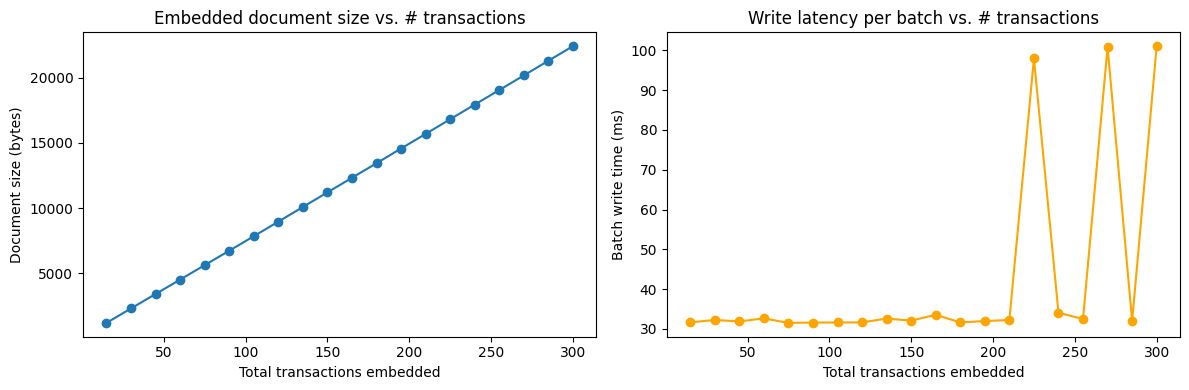

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
txn_counts = [(i + 1) * batch_size for i in range(n_batches)]

axes[0].plot(txn_counts, sizes, marker="o")
axes[0].set_title("Embedded document size vs. # transactions")
axes[0].set_xlabel("Total transactions embedded")
axes[0].set_ylabel("Document size (bytes)")

axes[1].plot(txn_counts, batch_times, marker="o", color="orange")
axes[1].set_title("Write latency per batch vs. # transactions")
axes[1].set_xlabel("Total transactions embedded")
axes[1].set_ylabel("Batch write time (ms)")

plt.tight_layout()
plt.show()

### 為什麼這是真實問題，而不只是理論上的疑慮

1. **16MB 文件大小上限。** 一筆典型的交易子文件，連同 BSON 欄位名稱的
   開銷在內，大約是 100～150 bytes。以每筆約 130 bytes 計算，大概在
   **每位顧客 120,000 筆交易**左右就會逼近 16MB 上限——對一般顧客來說
   這是每週幾筆、長達*數百年*才會發生的事，但對高交易量的**離群值**
   帳戶（例如每天固定幫整間辦公室訂餐的企業客戶）而言，幾個月內就
   輕易達標。詳見 Part 4.4。
2. **每次寫入都要重寫整個陣列。** 對一個持續成長的陣列做 `$push`，
   意味著每一次消費，都要讀取、修改、再把更多 bytes 寫回磁碟（並複寫
   到每個次要節點）——即使這次消費實際上只*新增*了幾百 bytes 的資料。
3. **無法有效率地查詢其中一段。**「顯示這位顧客最近 10 筆交易」意味著
   必須載入*整份*文件（不論多大），再於用戶端做切片——在大規模情境下，
   沒有辦法有效率地索引進陣列中間的某段資料，也沒辦法在不每次重新
   抓取整個陣列的情況下做分頁。
4. **工作集（working set）膨脹。** 即使只有一位顧客的陣列超大，也會讓
   `customers` 集合的平均文件大小暴增，拖累*所有*顧客（不只是那位
   離群值顧客）的 RAM 快取效率。

### 解法：把無界的關係搬到獨立的集合

這其實就是 Part 1 的「參照」決策、被正確套用而已：`Customer :
PointTransaction` 是 1:多且無界成長的關係 → 它應該屬於自己獨立的集合，
用 `customerId` 參照，而不是內嵌。

In [ ]:
db.point_transactions.drop()
db.point_transactions.create_index([("customerId", 1), ("timestamp", -1)])

all_txns = []
for b in range(n_batches):
    all_txns.extend(generate_point_transactions_for_customer(naive_customer_id, n=batch_size))

ref_batch_times = []
for i in range(0, len(all_txns), batch_size):
    batch = all_txns[i:i + batch_size]
    _, elapsed_ms = time_it(db.point_transactions.insert_many, batch)
    ref_batch_times.append(elapsed_ms)

print(f"獨立集合（參照）的每批寫入耗時："
      f"第一批={ref_batch_times[0]:.2f}ms，最後一批={ref_batch_times[-1]:.2f}ms "
      f"（不論歷史資料多少都維持平穩）")
naive_doc_no_history = db.customers_naive.find_one({"_id": naive_customer_id}, {"pointsHistory": 0})
print(f"顧客文件依然維持小巧：{doc_size_bytes(naive_doc_no_history)} bytes "
      f"（排除舊的內嵌陣列後）")

> **重點整理：** 如果一段子關係是**無界的**（沒有自然的、小規模的上限、
> 會一直成長），幾乎永遠都該放進它自己獨立的集合——不論它在概念上
> 感覺多麼「屬於」父文件。

---
## 4.2 計算模式（Computed Pattern）

### 問題

Part 3 的存取模式 #1（「載入顧客基本資料 + 目前點數餘額」）會在*每次
打開 App* 時發生——它必須夠快。但顧客的目前餘額其實是一個衍生值：
所有點數交易的累計總和。如果我們每次都即時計算它……

In [ ]:
# 準備一份較大且真實一點的資料集：顧客已經有訂單了（Part 2）；
# 現在為每位顧客建立 2,000 筆點數交易（共約 120,000 筆）。
db.point_transactions.drop()
db.point_transactions.create_index([("customerId", 1), ("timestamp", -1)])

TRANSACTIONS_PER_CUSTOMER = 2000
for c in customers:
    txns = generate_point_transactions_for_customer(
        c["_id"], n=TRANSACTIONS_PER_CUSTOMER
    )
    db.point_transactions.insert_many(txns)

sample_customer_id = customers[0]["_id"]
print(
    f"已為 {len(customers)} 位顧客建立 "
    f"{len(customers) * TRANSACTIONS_PER_CUSTOMER:,} 筆 point_transactions。"
)

In [ ]:
# 改善前：每次讀取都從點數交易紀錄即時計算顧客的累積點數。
# 下方會用 explain() 檢視這條聚合管線實際執行了多少工作。
pipeline = [
    {"$match": {"customerId": sample_customer_id}},
    {"$group": {
        "_id": "$customerId",
        "lifetimePoints": {"$sum": {"$cond": [{"$gt": ["$points", 0]}, "$points", 0]}},
        "txnCount": {"$sum": 1},
    }},
]

live_result = list(db.point_transactions.aggregate(pipeline))
print("即時聚合結果：", live_result)

In [ ]:
# 改善後：套用計算模式。在 customers.loyaltyStats 維護一份
# 預先計算、增量更新的彙總資料，而不是每次重新計算。

def record_point_transaction(db, customer_id, txn):
    """
    寫入一筆新交易，同時在同一個邏輯操作中，增量更新顧客文件上的
    預先計算彙總值（正式環境應該用多文件交易把這兩個寫入包起來，
    以確保原子性）。

    注意：`currentBalance` 是直接 $set 成帳本自身記錄的
    `balanceAfter`（而不是靠加總差額重新推算），這樣它就永遠不會
    跟最源頭的帳本資料產生落差，而且因為 `balanceAfter` 在交易建立
    時就已經做了下限為零的處理，所以餘額自然不會變成負數。
    """
    db.point_transactions.insert_one(txn)
    db.customers.update_one(
        {"_id": customer_id},
        {
            "$inc": {"loyaltyStats.lifetimePoints": max(txn["points"], 0)},
            "$set": {
                "loyaltyStats.currentBalance": txn["balanceAfter"],
                "loyaltyStats.lastComputedAt": datetime.now(timezone.utc),
            },
        },
    )

# 先用既有歷史資料把 loyaltyStats 回填一次（初始化），之後每一筆
# 「新」交易都用增量方式更新，而不需要重新計算。
for c in customers:
    agg = list(db.point_transactions.aggregate([
        {"$match": {"customerId": c["_id"]}},
        {"$group": {
            "_id": "$customerId",
            "lifetimePoints": {"$sum": {"$cond": [{"$gt": ["$points", 0]}, "$points", 0]}},
        }},
    ]))
    lifetime_points = agg[0]["lifetimePoints"] if agg else 0

    last_txn = db.point_transactions.find_one(
        {"customerId": c["_id"]}, sort=[("timestamp", -1)]
    )
    current_balance = last_txn["balanceAfter"] if last_txn else 0

    db.customers.update_one({"_id": c["_id"]}, {"$set": {
        "loyaltyStats.lifetimePoints": lifetime_points,
        "loyaltyStats.currentBalance": current_balance,
        "loyaltyStats.lastComputedAt": datetime.now(timezone.utc),
    }})

# 機制檢視：連到共用 Atlas 叢集時，牆鐘時間包含網路往返延遲。
# explain execution stats 則能顯示 MongoDB 在伺服器端為兩種策略實際
# 執行了多少工作，不受網路往返時間影響。
explain_live = db.command({
    "explain": {
        "aggregate": "point_transactions",
        "pipeline": pipeline,
        "cursor": {},
    },
    "verbosity": "executionStats",
})

explain_computed = db.customers.find(
    {"_id": sample_customer_id}, {"loyaltyStats": 1}
).explain()

# MongoDB 版本不同，聚合 explain 的 executionStats 可能位於不同位置：
# 較新的輸出可能放在頂層 executionStats，其他版本則放在 stages[]
# 的第一個 $cursor 階段；以下兩種格式都支援。
aggregate_stats = explain_live.get("executionStats")
if aggregate_stats is not None:
    live_execution_ms = aggregate_stats.get("executionTimeMillis")
    live_docs_examined = aggregate_stats.get("totalDocsExamined")
    live_keys_examined = aggregate_stats.get("totalKeysExamined")
else:
    stages = explain_live.get("stages", [])
    cursor_stage = next(
        (stage["$cursor"] for stage in stages if "$cursor" in stage), {}
    )
    cursor_stats = cursor_stage.get("executionStats", {})
    live_execution_ms = cursor_stats.get("executionTimeMillis", 0) + sum(
        stage.get("executionTimeMillisEstimate", 0) for stage in stages
    )
    live_docs_examined = cursor_stats.get("totalDocsExamined")
    live_keys_examined = cursor_stats.get("totalKeysExamined")

comparison_live = pd.DataFrame([{
    "label": "即時聚合（$match + $group）",
    "stage": "AGGREGATE",
    "executionTimeMillis": live_execution_ms,
    "totalDocsExamined": live_docs_examined,
    "totalKeysExamined": live_keys_examined,
    "nReturned": len(live_result),
}])
comparison_computed = explain_summary(
    explain_computed, label="計算模式（依索引查詢顧客）"
)
pd.concat([comparison_live, comparison_computed], ignore_index=True)

### 取捨

計算模式用一點點寫入端的額外工作（每筆交易多做一次 `$inc`），換取
App 中最熱門存取路徑的 O(1) 讀取效能。風險在於**資料漂移（drift）**：
如果有任何一筆交易是繞過 `record_point_transaction` 直接寫入的，
這份彙總資料就會悄悄地變得不準確。在正式環境中，建議搭配以下其中
一種做法：
- 用**多文件交易**把兩個寫入包在一起，或
- 建立一個**定期對帳工作（reconciliation job）**，重新計算並修正漂移。

### 📝 練習題 3

請把計算模式套用在存取模式 #4（記錄一筆新訂單）上。新增
`loyaltyStats.totalOrders` 與 `loyaltyStats.totalSpend` 欄位，讓它們
在每次下單時以增量方式更新，而不是靠聚合 `orders` 集合來計算。

<details>
<summary>✅ 點此展開解答</summary>

```python
def record_order(db, order_doc):
    db.orders.insert_one(order_doc)
    db.customers.update_one(
        {"_id": order_doc["customerRef"]["customerId"]},
        {
            "$inc": {
                "loyaltyStats.totalOrders": 1,
                "loyaltyStats.totalSpend": order_doc["total"],
            },
            "$set": {"loyaltyStats.lastComputedAt": datetime.now(timezone.utc)},
        },
    )
    # 訂單中「獲得點數」的那一部分，仍然透過唯一真實來源
    # record_point_transaction() 來記錄，因此 currentBalance /
    # lifetimePoints 永遠不會跟它失去同步。
```

概念跟 `record_point_transaction` 一樣：寫入路徑多做一點點工作
（`$inc` 三、四個計數器），讓儀表板／個人檔案畫面的讀取路徑，
始終是單一次有索引的文件查詢，不需要聚合運算。
</details>

---
## 4.3 屬性模式（Attribute Pattern）

### 問題

存取模式 #5：「瀏覽獎勵目錄，依資格條件篩選（等級、門市、星期幾、
通路……）」。不同獎勵的資格條件差異很大，而且行銷團隊會隨時間不斷
新增新的條件類型。天真的設計方式，是把每一種可能的條件都變成自己
的頂層欄位：

```json
{
  "_id": "RWD-1",
  "name": "Free Delivery",
  "minTier": "Silver",
  "minOrderValue": null,
  "validDayOfWeek": null,
  "eligibleStoreId": null,
  "channelRestriction": null
}
```

大多數欄位在大多數文件裡都是 `null`（稀疏），而且想要有效率地查詢，
你會需要**每個欄位各自建一個索引**（`minTier_1`、`minOrderValue_1`、
`validDayOfWeek_1`……）——維護成本很高，而且每次行銷想出新的條件類型，
你還是得改一次資料結構。

### 解法

**屬性模式**：把這些「形狀相似、只是名稱不同」的稀疏欄位，統一搬進
一個 `k`/`v`（鍵/值）陣列。一個**通用的複合索引**
`(attributes.k, attributes.v)`，就能涵蓋對任何條件（不論現有或未來
新增）的查詢。

In [ ]:
db.rewards.drop()

reward_eligibility_docs = [
    {"_id": "RWD-1", "name": "Free Delivery", "pointsCost": 75,
     "eligibility": [{"k": "minTier", "v": "Silver"}]},
    {"_id": "RWD-2", "name": "20% Off Order", "pointsCost": 200,
     "eligibility": [{"k": "minTier", "v": "Gold"}, {"k": "minOrderValue", "v": 15}]},
    {"_id": "RWD-3", "name": "Friday Zinger Deal", "pointsCost": 120,
     "eligibility": [{"k": "validDayOfWeek", "v": "Friday"}]},
    {"_id": "RWD-4", "name": "Drive-Thru Only Combo", "pointsCost": 100,
     "eligibility": [{"k": "channel", "v": "drive_thru"}]},
    {"_id": "RWD-5", "name": "Platinum VIP Bucket", "pointsCost": 300,
     "eligibility": [{"k": "minTier", "v": "Platinum"}]},
    {"_id": "RWD-6", "name": "Louisville Flagship Exclusive", "pointsCost": 90,
     "eligibility": [{"k": "eligibleStoreId", "v": "STORE-1000"}]},
]
db.rewards.insert_many(reward_eligibility_docs)

# 一個通用索引，就涵蓋了現在以及未來所有的資格條件。
db.rewards.create_index([("eligibility.k", 1), ("eligibility.v", 1)])
print("屬性模式的索引已建立。")

In [ ]:
# 查詢：適用於 Gold 等級顧客的獎勵
explain_gold = db.rewards.find(
    {"eligibility": {"$elemMatch": {"k": "minTier", "v": "Gold"}}}
).explain()
print("適用於 Gold 等級的獎勵：")
pprint_docs(db.rewards.find({"eligibility": {"$elemMatch": {"k": "minTier", "v": "Gold"}}}))

# 查詢：星期五適用的獎勵 -- 用同一個索引、不同的 k/v，完全不需要改資料結構
explain_friday = db.rewards.find(
    {"eligibility": {"$elemMatch": {"k": "validDayOfWeek", "v": "Friday"}}}
).explain()

comparison = pd.concat([
    explain_summary(explain_gold, label="minTier=Gold"),
    explain_summary(explain_friday, label="validDayOfWeek=Friday"),
], ignore_index=True)
comparison

兩個查詢都命中了 `IXSCAN`、而且用的是**同一個索引**，儘管篩選條件
完全不同。相比之下，天真的「每個條件一個頂層欄位」設計，每次行銷
想出新的資格規則，就得新建一個索引（還要做一次資料結構遷移）。

---
## 4.4 離群值模式（Outlier Pattern）

### 問題

存取模式 #2 說訂單要內嵌品項明細（Part 1 告訴我們 1～6 個品項是內嵌
的完美情境）。這對**99% 的訂單**來說都成立——但 KFC 也會承接辦公室、
活動用的**團體訂餐**，可能會有**超過 100 個品項**。如果讓這些訂單
照常內嵌：

In [42]:
# 一筆「正常」內嵌方式處理的團體訂單 -- 技術上合法，但看看跟一般訂單
# 相比，大小差異有多大。
catering_items = [
    {"sku": mi["_id"], "name": mi["name"], "qty": 20, "unitPrice": mi["price"]}
    for mi in (menu_items * 15)[:140]
]
catering_order_naive = {
    "_id": ObjectId(),
    "customerRef": {"customerId": customers[0]["_id"], "displayName": customers[0]["name"], "tier": customers[0]["tier"]},
    "storeId": stores[0]["_id"],
    "items": catering_items,
    "total": round(sum(i["qty"] * i["unitPrice"] for i in catering_items), 2),
    "orderedAt": datetime.now(timezone.utc),
}

typical_order = db.orders.find_one()
print(f"一般訂單大小：  {doc_size_bytes(typical_order):,} bytes（{len(typical_order['items'])} 個品項）")
print(f"團體訂單大小： {doc_size_bytes(catering_order_naive):,} bytes（{len(catering_order_naive['items'])} 個品項）")

一般訂單大小：  279 bytes（1 個品項）
團體訂單大小： 12,030 bytes（140 個品項）


這裡沒有任何一份文件觸及 16MB 上限——但只要把少數幾筆這樣的訂單混進
`orders` 集合，就會拉高整個集合的**平均文件大小**，拖累整個集合的
RAM 工作集效率（大多數讀取——例如「顯示最近訂單」列表畫面——對 99%
的訂單來說，只需要品項*數量*跟*總金額*，不需要每一筆品項明細）。
少數幾筆離群值，不應該讓每一個讀取者都為用不到的資料付出代價。

### 解法

**離群值模式**：針對常見情境做設計（小型、內嵌的品項陣列），偵測
文件何時變成離群值，翻轉一個旗標，然後把*溢出*的那部分資料搬到
獨立的集合，只有能處理離群值的程式路徑才需要去查詢它。

In [43]:
db.order_items_overflow.drop()
ITEM_THRESHOLD = 20

def save_order_with_overflow(db, order_doc):
    items = order_doc["items"]
    if len(items) <= ITEM_THRESHOLD:
        order_doc["hasMoreItems"] = False
        order_doc["itemCount"] = len(items)
        db.orders.insert_one(order_doc)
        return

    # 離群值：內嵌保留一份預覽，打上旗標，其餘的溢出到別處。
    order_doc["itemCount"] = len(items)
    order_doc["hasMoreItems"] = True
    order_doc["items"] = items[:ITEM_THRESHOLD]
    db.orders.insert_one(order_doc)
    db.order_items_overflow.insert_one({
        "orderId": order_doc["_id"],
        "items": items[ITEM_THRESHOLD:],
    })

def get_order_items(db, order_id):
    """應用層的讀取路徑：只有真正屬於離群值的訂單，才需要額外
    查詢 overflow 集合。"""
    order = db.orders.find_one({"_id": order_id})
    items = order["items"]
    if order.get("hasMoreItems"):
        overflow = db.order_items_overflow.find_one({"orderId": order_id})
        items = items + overflow["items"]
    return items

save_order_with_overflow(db, catering_order_naive)

stored_order = db.orders.find_one({"_id": catering_order_naive["_id"]})
print("儲存後的離群值訂單範例：")
pprint_doc(stored_order)
print(f"儲存後的訂單文件大小：{doc_size_bytes(stored_order):,} bytes "
      f"（內嵌品項數：{len(stored_order['items'])}，itemCount 旗標：{stored_order['itemCount']}）")

full_items = get_order_items(db, catering_order_naive["_id"])
print(f"get_order_items() 在需要時會透明地重組出全部 {len(full_items)} 個品項。")

儲存後的離群值訂單範例：
{
  "_id": "6adae19f5e0795028f24787b",
  "customerRef": {
    "customerId": "6adad2f95e0795028f227437",
    "displayName": "Melinda Cameron",
    "tier": "Bronze"
  },
  "storeId": "STORE-1000",
  "items": [
    {
      "sku": "ORC-8PC",
      "name": "8pc Original Recipe Bucket",
      "qty": 20,
      "unitPrice": 24.99
    },
    {
      "sku": "ZNG-BURGER",
      "name": "Zinger Burger",
      "qty": 20,
      "unitPrice": 7.49
    },
    {
      "sku": "POPCORN-L",
      "name": "Popcorn Chicken (Large)",
      "qty": 20,
      "unitPrice": 6.99
    },
    {
      "sku": "FAMOUS-BOWL",
      "name": "Famous Bowl",
      "qty": 20,
      "unitPrice": 5.99
    },
    {
      "sku": "TENDERS-3PC",
      "name": "3pc Extra Crispy Tenders",
      "qty": 20,
      "unitPrice": 6.49
    },
    {
      "sku": "BISCUIT",
      "name": "Buttermilk Biscuit",
      "qty": 20,
      "unitPrice": 1.99
    },
    {
      "sku": "MASHED-POTATO",
      "name": "Mashed Potatoes & Gravy

> **重點整理：** 資料模型設計，應該針對*典型*文件來設計，而不是針對
> 例外情況。當只有少數文件是真正的離群值時，請明確地處理它們
> （旗標 + overflow 集合），而不是讓這些少數例外決定了整個集合裡
> 每一份文件的樣貌。

---
## 4.5 繼承（多型）模式（Inheritance / Polymorphic Pattern）

### 問題

到目前為止，我們的 `rewards` 集合只有 `eligibility`（資格條件，
Part 4.3）。但獎勵其實還有真正不同的**類型**，每種類型都有自己
專屬的欄位：免費品項獎勵需要 `menuItemSku`；百分比折扣獎勵需要
`percentage`；免運費獎勵需要 `waivedFeeAmount`；買一送一（BOGO）
獎勵則需要 `eligibleSkus`。這些類型共用一份共同的「基礎」結構
（名稱、所需點數、有效期間），但在那之下就開始分歧。

### 解法

**繼承（多型）模式**：使用一個集合、一個 `type` 判別欄位，共用的
基礎欄位放在頂層，再加上一個該類型專屬的巢狀物件。用 `$jsonSchema`
搭配 `oneOf` 來強制規範每種類型該有的結構。

In [44]:
db.rewards.drop()

reward_validator = {
    "$jsonSchema": {
        "bsonType": "object",
        "required": ["_id", "type", "name", "pointsCost", "validFrom", "validTo"],
        "properties": {
            "type": {"enum": ["free_item", "percent_discount", "delivery_waiver", "bogo"]},
            "name": {"bsonType": "string"},
            "pointsCost": {"bsonType": "int", "minimum": 1},
        },
        "oneOf": [
            {"properties": {"type": {"enum": ["free_item"]}},
             "required": ["freeItem"]},
            {"properties": {"type": {"enum": ["percent_discount"]}},
             "required": ["percentDiscount"]},
            {"properties": {"type": {"enum": ["delivery_waiver"]}},
             "required": ["deliveryWaiver"]},
            {"properties": {"type": {"enum": ["bogo"]}},
             "required": ["bogo"]},
        ],
    }
}

db.create_collection("rewards", validator=reward_validator)
db.rewards.create_index([("type", 1)])

polymorphic_rewards = generate_polymorphic_rewards()
db.rewards.insert_many(polymorphic_rewards)
print(f"已新增 {len(polymorphic_rewards)} 筆多型獎勵文件。")
pprint_docs(db.rewards.find(), n=2)

已新增 4 筆多型獎勵文件。
{
  "_id": "RWD-FREE-TENDERS",
  "type": "free_item",
  "name": "Free 3pc Tenders",
  "pointsCost": 150,
  "validFrom": "2026-10-23T04:26:28.205000",
  "validTo": "2026-12-22T04:26:28.205000",
  "freeItem": {
    "sku": "TENDERS-3PC",
    "maxQtyPerRedemption": 1
  }
}
----------------------------------------
{
  "_id": "RWD-20-OFF",
  "type": "percent_discount",
  "name": "20% Off Entire Order",
  "pointsCost": 200,
  "validFrom": "2026-10-23T04:26:28.205000",
  "validTo": "2026-12-22T04:26:28.205000",
  "percentDiscount": {
    "percentage": 20,
    "maxDiscountAmount": 10.0
  }
}
----------------------------------------
... (2 of more shown)


In [45]:
# 跨類型查詢：獎勵目錄瀏覽畫面（存取模式 #5）
# 只想要「所有目前可兌換的獎勵」，不分類型。
print("所有獎勵（不分類型）：")
pprint_docs(db.rewards.find({}, {"name": 1, "type": 1, "pointsCost": 1}))

# 特定類型查詢：某種獎勵類型的兌換流程，確切知道該讀取哪個巢狀物件。
print("\n只看百分比折扣類型的獎勵：")
pprint_docs(db.rewards.find({"type": "percent_discount"}))

所有獎勵（不分類型）：
{
  "_id": "RWD-FREE-TENDERS",
  "type": "free_item",
  "name": "Free 3pc Tenders",
  "pointsCost": 150
}
----------------------------------------
{
  "_id": "RWD-20-OFF",
  "type": "percent_discount",
  "name": "20% Off Entire Order",
  "pointsCost": 200
}
----------------------------------------
{
  "_id": "RWD-FREE-DELIVERY",
  "type": "delivery_waiver",
  "name": "Free Delivery",
  "pointsCost": 75
}
----------------------------------------
{
  "_id": "RWD-BOGO-ZINGER",
  "type": "bogo",
  "name": "Buy One Get One Zinger Burger",
  "pointsCost": 180
}
----------------------------------------

只看百分比折扣類型的獎勵：
{
  "_id": "RWD-20-OFF",
  "type": "percent_discount",
  "name": "20% Off Entire Order",
  "pointsCost": 200,
  "validFrom": "2026-10-23T04:26:28.205000",
  "validTo": "2026-12-22T04:26:28.205000",
  "percentDiscount": {
    "percentage": 20,
    "maxDiscountAmount": 10.0
  }
}
----------------------------------------


In [46]:
# 資料結構驗證（schema validation）會強制每種類型都要帶有對應的必要巢狀物件。
from pymongo.errors import WriteError

malformed_reward = {
    "_id": "RWD-BAD",
    "type": "free_item",
    "name": "Broken Reward",
    "pointsCost": 50,
    "validFrom": datetime.now(timezone.utc),
    "validTo": datetime.now(timezone.utc),
    # 缺少這個類型所需要的 "freeItem" 巢狀物件！
}

try:
    db.rewards.insert_one(malformed_reward)
except WriteError as e:
    print("插入被 $jsonSchema 驗證規則拒絕，符合預期：")
    print(f"  {e.details.get('errmsg', str(e))}")

插入被 $jsonSchema 驗證規則拒絕，符合預期：
  Document failed validation


注意這裡如何跟 4.3 的屬性模式組合在一起——在真實系統中，每一份獎勵
文件都會**同時**帶有一個 `type` 判別的結構（繼承模式，用於核心的
兌換邏輯）**以及**一個 `eligibility` 陣列（屬性模式，用於彈性的
目錄篩選邏輯）。各種模式並非互斥關係；正式環境的資料模型，通常會
在同一個集合上疊加好幾種模式。

---
# Part 5 — 最終整合資料模型

### 模式總回顧

| 模式 | 解決的問題 | 我們套用的位置 |
|---|---|---|
| **參照（Referencing）** | 無界的 1:多關係 | `Customer → Orders`、`Customer → PointTransactions` |
| **延伸參照（Extended Reference）** | 避免為了頻繁顯示、變動緩慢的欄位而做 `$lookup` | `Order.customerRef`（姓名、等級）、`Order.storeRef`（名稱、城市） |
| **無界陣列（反模式）** | 若內嵌一段會持續成長的子集合會發生什麼事 | `Customer.pointsHistory[]` — 透過抽離成 `point_transactions` 來修正 |
| **計算模式（Computed）** | 避免在熱門讀取路徑上做昂貴的即時聚合 | `Customer.loyaltyStats`（lifetimePoints、currentBalance、totalOrders） |
| **屬性模式（Attribute）** | 許多稀疏、形狀相似、需要通用查詢方式的可選欄位 | `Reward.eligibility[]`（minTier、minOrderValue、validDayOfWeek……） |
| **離群值模式（Outlier）** | 少數文件需要遠超過一般文件所需的資料量 | `Order.items[]` + `order_items_overflow`（用於團體訂餐） |
| **繼承（多型）模式** | 多個相關子類型共用一份基礎結構、但在其下各自分歧 | `Reward.type` 判別欄位（free_item / percent_discount / delivery_waiver / bogo） |

### 最終的集合清單

| 集合 | 用途 |
|---|---|
| `customers` | 基本資料、會員等級、預先計算好的 `loyaltyStats` |
| `stores` | 實體門市據點 |
| `menu_items` | 商品目錄 |
| `orders` | 消費紀錄，內含延伸參照的顧客／門市快照，以及能處理離群值的品項結構 |
| `order_items_overflow` | 離群值（團體訂餐）訂單的溢出品項明細 |
| `point_transactions` | 只增不改的累積／兌換帳本，用 `customerId` 參照 |
| `rewards` | 多型的獎勵目錄，附帶資格屬性 |
| `redemptions` | 顧客兌換某項獎勵的紀錄（參照 `customerId` + `rewardId`） |

### 📝 期末綜合練習：推薦好友計畫

KFC 想要新增一個**「推薦好友」**功能：現有顧客分享一組推薦碼；當新
顧客用這組推薦碼註冊、並完成第一筆訂單後，推薦人與被推薦人都能獲得
點數獎勵。

請設計支援這個功能所需的資料模型變更，具體回答以下問題：

1. 推薦關係應該放在哪裡——新增欄位、新增集合，還是兩者都要？
2. 你會套用今天學到的哪個（或哪些）模式？為什麼？
3. 要如何有效率地回答：「顧客 X 成功推薦了多少人？透過推薦功能總共
   賺了多少點數獎勵？」

請先自己畫出草圖（用 markdown／JSON 描述即可，寫程式碼則是加分項），
再對照解答。

**完整的書面解答在 repo 根目錄的
[`CAPSTONE_SOLUTION.zh-TW.md`](../CAPSTONE_SOLUTION.zh-TW.md)**
（英文版請見 `CAPSTONE_SOLUTION.md`）——建議先自己動手試試看！

In [ ]:
# ✍️ 把你的期末綜合練習設計寫在這裡（markdown 草圖、範例文件，
# 和／或程式碼都可以）。完成後再對照 CAPSTONE_SOLUTION.md。

---
# Part 6 — 總結

### 決策檢查清單

**內嵌 vs. 參照**
- [ ] 這個關係是 1:1 或 1:少量、有界、且總是一起讀取的嗎？ → **內嵌**
- [ ] 這個關係是 1:多／無界，或是會獨立於父文件被查詢的嗎？ → **參照**
- [ ] 你是否每次讀取都需要某個參照對象的顯示欄位，而且它很少變動？ → **延伸參照**

**出現以下情境時，考慮套用對應模式……**
- [ ] 熱門讀取路徑需要一個「原本得每次即時計算」的值 → **計算模式**
- [ ] 很多可選、形狀相似、需要彈性／通用查詢方式的欄位 → **屬性模式**
- [ ] 少數文件需要的資料量遠超過一般典型文件 → **離群值模式**
- [ ] 多個子類型共用一份基礎結構，但各自在其下分歧 → **繼承（多型）模式**

**要避開的警訊**
- [ ] 文件內有一個陣列，每發生一次事件就新增一筆、永不停止、沒有自然
  上限 → **無界陣列反模式** — 把它搬到自己獨立的參照集合。

### 今天學到的內容

1. 內嵌 vs. 參照的決策框架，以及用延伸參照模式解決「我需要 join、
   但不想為它付出代價」這個問題。
2. 從具體的存取模式出發來驅動資料模型設計，而不只是從實體關係出發。
3. 四種正式環境等級的資料模型模式（計算模式、屬性模式、離群值模式、
   繼承模式），以及一種經典反模式（無界陣列），全部都在同一套
   連貫一致的忠誠度平台資料模型上完整演示過一遍。

感謝參加！🍗